# Shoplifting Detection Using Pretrained VideoMAE
## Week 6 — Transfer Learning & Fine-Tuning

### Objective
Fine-tune a pretrained video classification model to distinguish
between normal shopping behavior and shoplifting activities.

### Approach
- Model: VideoMAE pretrained on Kinetics-400
- Framework: PyTorch + Hugging Face Transformers
- Classes: Normal Shopping (0), Shoplifting (1)
- Baseline: Week 5 Custom 3D CNN
- Target: F1-Score > 84.54%

## Before running
**Environment:** Kaggle with two Tesla T4 GPUs for the recorded run; attach the shoplifting dataset and Week 5 checkpoint.

**Reproduction:** Enable internet for the first Hugging Face model download. Run cells in order. This notebook contains **saved outputs from a completed Kaggle run**. Fresh runs can vary because clip-level augmentation is not fully deterministic. The notebook exports `week6_split_manifest.csv` to `/kaggle/working/` during execution; retain this file for future comparisons.

**Evaluation limitation:** Week 5 CNN is re-evaluated on the same Week 6 test videos, but the Week 5 original training manifest is unavailable, so its training/test independence cannot be fully verified.


In [1]:
%pip install -q "transformers==5.16.1" accelerate scikit-learn opencv-python-headless safetensors seaborn


Note: you may need to restart the kernel to use updated packages.


In [2]:

import os
import re
import random
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from transformers import (
    VideoMAEForVideoClassification,
    VideoMAEImageProcessor
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Hardware
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("WEEK 6 — PRETRAINED VIDEO CLASSIFICATION")
print("=" * 60)

print("PyTorch version :", torch.__version__)
print("Device          :", device)

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable GPU in Kaggle settings.")

print("=" * 60)

import transformers
print("transformers version:",transformers.__version__)


WEEK 6 — PRETRAINED VIDEO CLASSIFICATION
PyTorch version : 2.11.0+cu128
Device          : cuda
GPU             : Tesla T4
transformers version: 5.16.1


In [3]:

# ============================================================
# CELL 3 — DATASET VERIFICATION
# ============================================================

DATASET_PATH = (
    "/kaggle/input/datasets/nebalelshobary/"
    "shoplifting-detection-dataset"
)

CLASSES = {
    "non shop lifters": 0,
    "shop lifters": 1
}

print("=" * 60)
print("DATASET VERIFICATION")
print("=" * 60)

assert os.path.isdir(DATASET_PATH), (
    f"Dataset not found: {DATASET_PATH}"
)

total_videos = 0

for class_name, label in CLASSES.items():

    class_path = os.path.join(
        DATASET_PATH,
        class_name
    )

    assert os.path.isdir(class_path), (
        f"Missing class folder: {class_path}"
    )

    videos = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(
            (".mp4", ".avi", ".mov", ".mkv")
        )
    ]

    print(f"\nClass: {class_name}")
    print(f"Label: {label}")
    print(f"Videos: {len(videos)}")

    total_videos += len(videos)

print("\n" + "=" * 60)
print("Total videos:", total_videos)
print("Dataset verification completed!")


DATASET VERIFICATION

Class: non shop lifters
Label: 0
Videos: 531

Class: shop lifters
Label: 1
Videos: 324

Total videos: 855
Dataset verification completed!


In [4]:

# ============================================================
# CELL 4 — LOAD PRETRAINED VIDEOMAE
# ============================================================

MODEL_NAME = "MCG-NJU/videomae-base-finetuned-kinetics"

id2label = {
    0: "Normal",
    1: "Shoplifting"
}

label2id = {
    "Normal": 0,
    "Shoplifting": 1
}

# Load the pretrained image processor
image_processor = VideoMAEImageProcessor.from_pretrained(
    MODEL_NAME
)

# Load pretrained VideoMAE
# Replace the original classification head with 2 outputs
model = VideoMAEForVideoClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

model = model.to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("PRETRAINED VIDEOMAE INITIALIZED")
print("=" * 60)

print("Model:", MODEL_NAME)
print("Number of classes:", model.config.num_labels)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Classifier:", model.classifier)

assert model.config.num_labels == 2
assert model.classifier.out_features == 2

print("\nPretrained model loaded successfully!")
print("=" * 60)

import transformers
print("Transformers version:", transformers.__version__)
print("PyTorch version:", torch.__version__)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key                                                            | Status     |                                                                                         
---------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    |                                                                                         
videomae.encoder.layer.{0...11}.attention.attention.query.bi

PRETRAINED VIDEOMAE INITIALIZED
Model: MCG-NJU/videomae-base-finetuned-kinetics
Number of classes: 2
Total parameters: 86,237,954
Trainable parameters: 86,237,954
Classifier: Linear(in_features=768, out_features=2, bias=True)

Pretrained model loaded successfully!
Transformers version: 5.16.1
PyTorch version: 2.11.0+cu128


In [5]:

# ============================================================
# CELL 4B — FIX PRETRAINED ATTENTION BIAS WEIGHTS
# ============================================================

import torch
from huggingface_hub import hf_hub_download
from safetensors import safe_open

# Get the downloaded pretrained checkpoint
checkpoint_path = hf_hub_download(
    repo_id=MODEL_NAME,
    filename="model.safetensors",
    local_files_only=True
)

model_state = model.state_dict()
fixed_layers = 0

with safe_open(
    checkpoint_path,
    framework="pt",
    device="cpu"
) as checkpoint:

    with torch.no_grad():

        for i in range(model.config.num_hidden_layers):

            prefix = (
                f"videomae.encoder.layer.{i}."
                "attention.attention."
            )

            # Original checkpoint names
            q_source = prefix + "q_bias"
            v_source = prefix + "v_bias"

            # Current Transformers model names
            q_target = prefix + "query.bias"
            k_target = prefix + "key.bias"
            v_target = prefix + "value.bias"

            assert q_source in checkpoint.keys()
            assert v_source in checkpoint.keys()

            assert q_target in model_state
            assert k_target in model_state
            assert v_target in model_state

            # Restore pretrained query bias
            q_weights = checkpoint.get_tensor(q_source)

            model_state[q_target].copy_(
                q_weights.to(model_state[q_target].device)
            )

            # Restore pretrained value bias
            v_weights = checkpoint.get_tensor(v_source)

            model_state[v_target].copy_(
                v_weights.to(model_state[v_target].device)
            )

            # Original architecture used no key bias
            model_state[k_target].zero_()

            fixed_layers += 1

print("=" * 60)
print("VIDEOMAE ATTENTION COMPATIBILITY FIX")
print("=" * 60)

print("Attention layers corrected:", fixed_layers)
print("Query biases: Restored")
print("Value biases: Restored")
print("Key biases: Set to zero")

assert fixed_layers == model.config.num_hidden_layers

print("\nAttention bias compatibility fix completed!")


VIDEOMAE ATTENTION COMPATIBILITY FIX
Attention layers corrected: 12
Query biases: Restored
Value biases: Restored
Key biases: Set to zero

Attention bias compatibility fix completed!


In [6]:

# ============================================================
# CELL 5 — RECREATE GROUP-AWARE DATASET SPLIT
# ============================================================

import os
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

RANDOM_SEED = 42

def extract_source_id(filename):
    name = os.path.splitext(filename)[0]
    match = re.match(r"^(.*_\d+)_\d+$", name)
    return match.group(1) if match else name


records = []

for class_name, label in CLASSES.items():
    folder = os.path.join(DATASET_PATH, class_name)

    # Week 5 used os.listdir without sorting.
    for filename in os.listdir(folder):
        video_path = os.path.join(folder, filename)

        if not os.path.isfile(video_path):
            continue

        if not filename.lower().endswith(
            (".mp4", ".avi", ".mov", ".mkv")
        ):
            continue

        cap = cv2.VideoCapture(video_path)
        readable = cap.isOpened()
        cap.release()

        if readable:
            records.append({
                "Video": filename,
                "Class": class_name,
                "Label": label
            })

df = pd.DataFrame(records)

df["Source_ID"] = df["Video"].apply(extract_source_id)

df["Group_ID"] = (
    df["Class"] + "/" + df["Source_ID"]
)


def choose_group_split(data, target_fraction, seed):
    best = None
    positive_rate = data["Label"].mean()

    for n_splits in [5, 6, 7]:

        splitter = StratifiedGroupKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed
        )

        for train_idx, holdout_idx in splitter.split(
            data,
            data["Label"],
            groups=data["Group_ID"]
        ):

            holdout = data.iloc[holdout_idx]

            size_error = abs(
                len(holdout) / len(data) - target_fraction
            )

            balance_error = abs(
                holdout["Label"].mean() - positive_rate
            )

            score = size_error + balance_error

            if best is None or score < best[0]:
                best = (score, train_idx, holdout_idx)

    return best[1], best[2]


# Test split
remaining_idx, test_idx = choose_group_split(
    df,
    target_fraction=0.15,
    seed=RANDOM_SEED
)

remaining_df = df.iloc[remaining_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Validation split
train_idx, val_idx = choose_group_split(
    remaining_df,
    target_fraction=0.15 / 0.85,
    seed=RANDOM_SEED + 1
)

train_df = remaining_df.iloc[train_idx].reset_index(drop=True)
val_df = remaining_df.iloc[val_idx].reset_index(drop=True)

# Validate no group leakage
assert set(train_df.Group_ID).isdisjoint(val_df.Group_ID)
assert set(train_df.Group_ID).isdisjoint(test_df.Group_ID)
assert set(val_df.Group_ID).isdisjoint(test_df.Group_ID)

assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"{name}: {len(subset)} videos")
    print(subset["Label"].value_counts().sort_index())

print("\nTotal:", len(df))
print("No group leakage detected.")

# Save split manifest for reproducibility
split_manifest = pd.concat([
    train_df.assign(Split="train"),
    val_df.assign(Split="validation"),
    test_df.assign(Split="test")
], ignore_index=True)

split_manifest.to_csv(
    "/kaggle/working/week6_split_manifest.csv",
    index=False
)

print("Split manifest saved.")


DATASET SPLIT
Training: 611 videos
Label
0    379
1    232
Name: count, dtype: int64
Validation: 122 videos
Label
0    76
1    46
Name: count, dtype: int64
Testing: 122 videos
Label
0    76
1    46
Name: count, dtype: int64

Total: 855
No group leakage detected.
Split manifest saved.


In [7]:

# ============================================================
# CELL 6 — VIDEOMAE PREPROCESSING
# ============================================================

NUM_FRAMES = 16
FRAME_SIZE = (224, 224)


def resize_with_padding(frame, target_size=(224, 224)):
    target_w, target_h = target_size
    h, w = frame.shape[:2]

    scale = min(target_w / w, target_h / h)

    new_w = max(1, min(target_w, round(w * scale)))
    new_h = max(1, min(target_h, round(h * scale)))

    interpolation = (
        cv2.INTER_AREA if scale < 1
        else cv2.INTER_LINEAR
    )

    resized = cv2.resize(
        frame,
        (new_w, new_h),
        interpolation=interpolation
    )

    pad_left = (target_w - new_w) // 2
    pad_top = (target_h - new_h) // 2

    return cv2.copyMakeBorder(
        resized,
        pad_top,
        target_h - new_h - pad_top,
        pad_left,
        target_w - new_w - pad_left,
        cv2.BORDER_CONSTANT,
        value=(0, 0, 0)
    )


def sample_video_frames(video_path, num_frames=16):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError(f"Cannot open: {video_path}")

    try:
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total <= 0:
            raise ValueError(f"Empty video: {video_path}")

        indices = np.linspace(
            0, total - 1, num_frames
        ).astype(np.int64)

        frames = []

        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            success, frame = cap.read()

            if not success:
                raise RuntimeError(
                    f"Cannot read frame {idx}: {video_path}"
                )

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = resize_with_padding(frame, FRAME_SIZE)
            frames.append(frame)

        return np.stack(frames), indices

    finally:
        cap.release()


def augment_video_consistently(frames):
    rng = np.random.default_rng()
    T, H, W, C = frames.shape

    flip = rng.random() < 0.5

    scale = rng.uniform(0.90, 1.00)
    crop_h = max(1, int(H * scale))
    crop_w = max(1, int(W * scale))

    top = int(rng.integers(0, H - crop_h + 1))
    left = int(rng.integers(0, W - crop_w + 1))

    brightness = rng.uniform(0.90, 1.10)
    contrast = rng.uniform(0.90, 1.10)
    saturation = rng.uniform(0.90, 1.10)

    result = []

    for frame in frames:
        image = frame[top:top+crop_h, left:left+crop_w]
        image = cv2.resize(image, (W, H))

        if flip:
            image = cv2.flip(image, 1)

        image = image.astype(np.float32)

        image = (
            (image - 127.5) * contrast + 127.5
        ) * brightness

        image = np.clip(image, 0, 255).astype(np.uint8)

        hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
        hsv = hsv.astype(np.float32)
        hsv[:, :, 1] = np.clip(
            hsv[:, :, 1] * saturation, 0, 255
        )

        image = cv2.cvtColor(
            hsv.astype(np.uint8), cv2.COLOR_HSV2RGB
        )

        result.append(image)

    return np.stack(result)


print("VideoMAE preprocessing functions ready!")
print("Frames:", NUM_FRAMES)
print("Resolution:", FRAME_SIZE)


VideoMAE preprocessing functions ready!
Frames: 16
Resolution: (224, 224)


In [8]:

# ============================================================
# CELL 7 — VIDEOMAE DATASET
# ============================================================

class VideoMAEShopliftingDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        video_path = os.path.join(
            DATASET_PATH,
            row["Class"],
            row["Video"]
        )

        frames, _ = sample_video_frames(
            video_path,
            num_frames=NUM_FRAMES
        )

        if self.augment:
            frames = augment_video_consistently(frames)

        # Pretrained VideoMAE normalization
        processed = image_processor(
            list(frames),
            return_tensors="pt",
            do_resize=False,
            do_center_crop=False
        )

        pixel_values = processed["pixel_values"].squeeze(0)

        label = torch.tensor(
            int(row["Label"]),
            dtype=torch.long
        )

        return pixel_values, label


train_dataset = VideoMAEShopliftingDataset(
    train_df,
    augment=True
)

val_dataset = VideoMAEShopliftingDataset(
    val_df,
    augment=False
)

test_dataset = VideoMAEShopliftingDataset(
    test_df,
    augment=False
)

print("=" * 55)
print("VIDEOMAE DATASETS")
print("=" * 55)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Datasets initialized successfully!")


VIDEOMAE DATASETS
Train: 611
Validation: 122
Test: 122
Datasets initialized successfully!


In [9]:

# ============================================================
# CELL 8 — DATASET VALIDATION
# ============================================================

video, label = train_dataset[0]

print("=" * 55)
print("VIDEOMAE DATASET VALIDATION")
print("=" * 55)

print("Video shape:", tuple(video.shape))
print("Data type:", video.dtype)
print("Label:", label.item())
print("Pixel range:", video.min().item(), video.max().item())

expected_shape = (16, 3, 224, 224)

assert video.shape == expected_shape, (
    f"Unexpected shape: {video.shape}"
)
assert torch.isfinite(video).all()
assert label.item() in [0, 1]

print("\nAll validation checks passed!")


VIDEOMAE DATASET VALIDATION
Video shape: (16, 3, 224, 224)
Data type: torch.float32
Label: 0
Pixel range: -2.015155553817749 2.2914161682128906

All validation checks passed!


In [10]:

# ============================================================
# CELL 9 — VERIFY DATASET SPLIT (CORRECTED)
# ============================================================

import os
import pandas as pd

print("=" * 65)
print("DATASET SPLIT VERIFICATION")
print("=" * 65)

# Get actual dataframes from our Dataset class
train_data = train_dataset.dataframe.copy()
val_data = val_dataset.dataframe.copy()
test_data = test_dataset.dataframe.copy()

# Build unique video identifiers
def get_video_ids(dataframe):
    return set(
        dataframe["Class"].astype(str)
        + "/"
        + dataframe["Video"].astype(str)
    )

train_ids = get_video_ids(train_data)
val_ids = get_video_ids(val_data)
test_ids = get_video_ids(test_data)

# Check overlap between splits
train_val_overlap = train_ids & val_ids
train_test_overlap = train_ids & test_ids
val_test_overlap = val_ids & test_ids

print("\nDataset Sizes:")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

print("\nUnique Video Counts:")
print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))

print("\nExact Video Overlap:")
print("Train / Validation:", len(train_val_overlap))
print("Train / Test:", len(train_test_overlap))
print("Validation / Test:", len(val_test_overlap))

# Check original recording groups
train_groups = set(train_data["Group_ID"])
val_groups = set(val_data["Group_ID"])
test_groups = set(test_data["Group_ID"])

print("\nSource Group Overlap:")
print("Train / Validation:", len(train_groups & val_groups))
print("Train / Test:", len(train_groups & test_groups))
print("Validation / Test:", len(val_groups & test_groups))

# Ensure all videos belong to one split
assert len(train_ids) == len(train_data)
assert len(val_ids) == len(val_data)
assert len(test_ids) == len(test_data)

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("\nPASS: No exact video or source-group overlap!")

# Save test file manifest
test_manifest = test_data[
    ["Class", "Video", "Label", "Source_ID", "Group_ID"]
].copy()

test_manifest = test_manifest.sort_values(
    ["Class", "Video"]
).reset_index(drop=True)

output_path = (
    "/kaggle/working/videomae_test_video_list.csv"
)

test_manifest.to_csv(output_path, index=False)

print("\nTest manifest saved:", output_path)
print("Total test videos:", len(test_manifest))

print("\nNOTE:")
print("Week 6 internal split checks passed.")
print("Week 5 test identity is not verified; cross-week metrics are reported with this limitation.")


DATASET SPLIT VERIFICATION

Dataset Sizes:
Training: 611
Validation: 122
Testing: 122

Unique Video Counts:
Train: 611
Validation: 122
Test: 122

Exact Video Overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Source Group Overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

PASS: No exact video or source-group overlap!

Test manifest saved: /kaggle/working/videomae_test_video_list.csv
Total test videos: 122

NOTE:
Week 6 internal split checks passed.
Week 5 test identity is not verified; cross-week metrics are reported with this limitation.


In [11]:
# ============================================================
# CELL 10 — FINE-TUNING CONFIGURATION
# ============================================================
EPOCHS = 10
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
criterion = nn.CrossEntropyLoss()
BEST_MODEL_PATH = "/kaggle/working/best_videomae_shoplifting.pth"

print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Best checkpoint:", BEST_MODEL_PATH)

Epochs: 10
Learning rate: 2e-05
Weight decay: 0.01
Best checkpoint: /kaggle/working/best_videomae_shoplifting.pth


In [12]:

# ============================================================
# CELL 11 — ENABLE DUAL GPU TRAINING
# ============================================================

import torch
import torch.nn as nn

# Number of available GPUs
gpu_count = torch.cuda.device_count()

# Enable DataParallel
if gpu_count > 1 and not isinstance(model, nn.DataParallel):
    model = nn.DataParallel(
        model,
        device_ids=list(range(gpu_count))
    )
    print(f"DataParallel enabled on {gpu_count} GPUs")
else:
    print("Single GPU training enabled")

model = model.to(device)

# Increase total batch size
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Recreate optimizer after configuring parallel training
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("\n" + "=" * 55)
print("DUAL GPU TRAINING CONFIGURATION")
print("=" * 55)

print("GPUs:", gpu_count)
print("Model:", type(model).__name__)
print("Total batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("\nDual GPU setup completed successfully!")


DataParallel enabled on 2 GPUs

DUAL GPU TRAINING CONFIGURATION
GPUs: 2
Model: DataParallel
Total batch size: 4
Training batches: 153
Validation batches: 31
Testing batches: 31

Dual GPU setup completed successfully!


In [13]:

# ============================================================
# CELL 12 — VIDEOMAE FINE-TUNING & VALIDATION
# ============================================================

from tqdm.auto import tqdm
from sklearn.metrics import f1_score
import time
import torch
import os

# Mixed precision settings
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# Reset training tracking
best_val_f1 = -1.0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_f1": []
}

print("=" * 60)
print("STARTING VIDEOMAE FINE-TUNING")
print("=" * 60)
print("GPUs:", torch.cuda.device_count())
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Mixed Precision:", use_amp)
print("=" * 60)

for epoch in range(EPOCHS):

    start_time = time.time()

    # =========================
    # TRAINING
    # =========================
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"
    )

    for videos, labels in train_bar:

        videos = videos.to(
            device, non_blocking=True
        )
        labels = labels.to(
            device, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            enabled=use_amp
        ):
            outputs = model(pixel_values=videos)
            logits = outputs.logits
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"
        )

        for videos, labels in val_bar:

            videos = videos.to(
                device, non_blocking=True
            )
            labels = labels.to(
                device, non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                enabled=use_amp
            ):
                outputs = model(pixel_values=videos)
                logits = outputs.logits
                loss = criterion(logits, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

            all_preds.extend(
                logits.argmax(dim=1).cpu().tolist()
            )
            all_labels.extend(
                labels.cpu().tolist()
            )

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    val_f1 = f1_score(
        all_labels,
        all_preds,
        average="binary",
        zero_division=0
    )

    scheduler.step()

    # =========================
    # SAVE TRAINING HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        actual_model = (
            model.module
            if isinstance(model, torch.nn.DataParallel)
            else model
        )

        torch.save(
            actual_model.state_dict(),
            BEST_MODEL_PATH
        )

        print(
            f"Best model saved! "
            f"Validation F1: {best_val_f1:.4f}"
        )

    elapsed = time.time() - start_time

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch+1}/{EPOCHS} RESULTS")
    print("=" * 60)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")
    print(f"Val F1-score: {val_f1:.4f}")
    print(f"Best Val F1: {best_val_f1:.4f}")
    print(f"Epoch Time: {elapsed:.1f} seconds")

print("\nFine-tuning completed!")
print("Best Validation F1:", best_val_f1)
print("Best model:", BEST_MODEL_PATH)


STARTING VIDEOMAE FINE-TUNING
GPUs: 2
Batch size: 4
Epochs: 10
Mixed Precision: True


Epoch 1/10 [Train]:   0%|          | 0/153 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/31 [00:00<?, ?it/s]

Best model saved! Validation F1: 0.6571

EPOCH 1/10 RESULTS
Train Loss: 0.6402
Train Accuracy: 0.6367
Val Loss: 0.4859
Val Accuracy: 0.8033
Val F1-score: 0.6571
Best Val F1: 0.6571
Epoch Time: 507.2 seconds


Epoch 2/10 [Train]:   0%|          | 0/153 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/31 [00:00<?, ?it/s]


EPOCH 9/10 RESULTS
Train Loss: 0.0294
Train Accuracy: 0.9935
Val Loss: 0.0826
Val Accuracy: 0.9754
Val F1-score: 0.9663
Best Val F1: 0.9663
Epoch Time: 361.3 seconds


Epoch 10/10 [Train]:   0%|          | 0/153 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/31 [00:00<?, ?it/s]


EPOCH 10/10 RESULTS
Train Loss: 0.0279
Train Accuracy: 0.9951
Val Loss: 0.0685
Val Accuracy: 0.9754
Val F1-score: 0.9663
Best Val F1: 0.9663
Epoch Time: 353.0 seconds

Fine-tuning completed!
Best Validation F1: 0.9662921348314607
Best model: /kaggle/working/best_videomae_shoplifting.pth


In [14]:

# ============================================================
# CELL 13 — EVALUATE BEST VIDEOMAE ON TEST SET
# ============================================================

import os
import time
import torch
import numpy as np

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load best saved weights
assert os.path.exists(BEST_MODEL_PATH), \
    "Best model checkpoint not found!"

actual_model = (
    model.module
    if isinstance(model, torch.nn.DataParallel)
    else model
)

state_dict = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

actual_model.load_state_dict(state_dict)
model.eval()

model_size_mb = os.path.getsize(BEST_MODEL_PATH) / (1024 ** 2)
print("Best VideoMAE model loaded successfully!")

# 2. Test evaluation
all_test_labels = []
all_test_preds = []

total_inference_time = 0.0
total_test_videos = 0

with torch.inference_mode():

    for videos, labels in tqdm(
        test_loader,
        desc="Evaluating Test Set"
    ):

        videos = videos.to(
            device, non_blocking=True
        )

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        with torch.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            outputs = model(pixel_values=videos)
            logits = outputs.logits

        if device.type == "cuda":
            torch.cuda.synchronize()

        total_inference_time += (
            time.perf_counter() - start_time
        )

        predictions = torch.argmax(
            logits, dim=1
        )

        all_test_preds.extend(
            predictions.cpu().tolist()
        )

        all_test_labels.extend(
            labels.cpu().tolist()
        )

        total_test_videos += len(labels)

# 3. Calculate test metrics
test_accuracy = accuracy_score(
    all_test_labels, all_test_preds
)

test_precision = precision_score(
    all_test_labels,
    all_test_preds,
    zero_division=0
)

test_recall = recall_score(
    all_test_labels,
    all_test_preds,
    zero_division=0
)

test_f1 = f1_score(
    all_test_labels,
    all_test_preds,
    zero_division=0
)

test_cm = confusion_matrix(
    all_test_labels,
    all_test_preds,
    labels=[0, 1]
)

avg_inference_time = (
    total_inference_time / total_test_videos
)

# 4. Display results
print("\n" + "=" * 60)
print("BEST VIDEOMAE — TEST RESULTS")
print("=" * 60)

print(f"Test Videos: {total_test_videos}")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")

print("\nConfusion Matrix:")
print(test_cm)

print("\nClassification Report:")
print(
    classification_report(
        all_test_labels,
        all_test_preds,
        labels=[0, 1],
        target_names=["Normal", "Shoplifting"],
        zero_division=0
    )
)

print(
    f"\nAverage GPU inference time per video: "
    f"{avg_inference_time:.4f} seconds"
)

print("\nTest evaluation completed!")


Best VideoMAE model loaded successfully!


Evaluating Test Set:   0%|          | 0/31 [00:00<?, ?it/s]


BEST VIDEOMAE — TEST RESULTS
Test Videos: 122
Accuracy:  0.9672
Precision: 1.0000
Recall:    0.9130
F1-score:  0.9545

Confusion Matrix:
[[76  0]
 [ 4 42]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      1.00      0.97        76
 Shoplifting       1.00      0.91      0.95        46

    accuracy                           0.97       122
   macro avg       0.97      0.96      0.96       122
weighted avg       0.97      0.97      0.97       122


Average GPU inference time per video: 0.0296 seconds

Test evaluation completed!


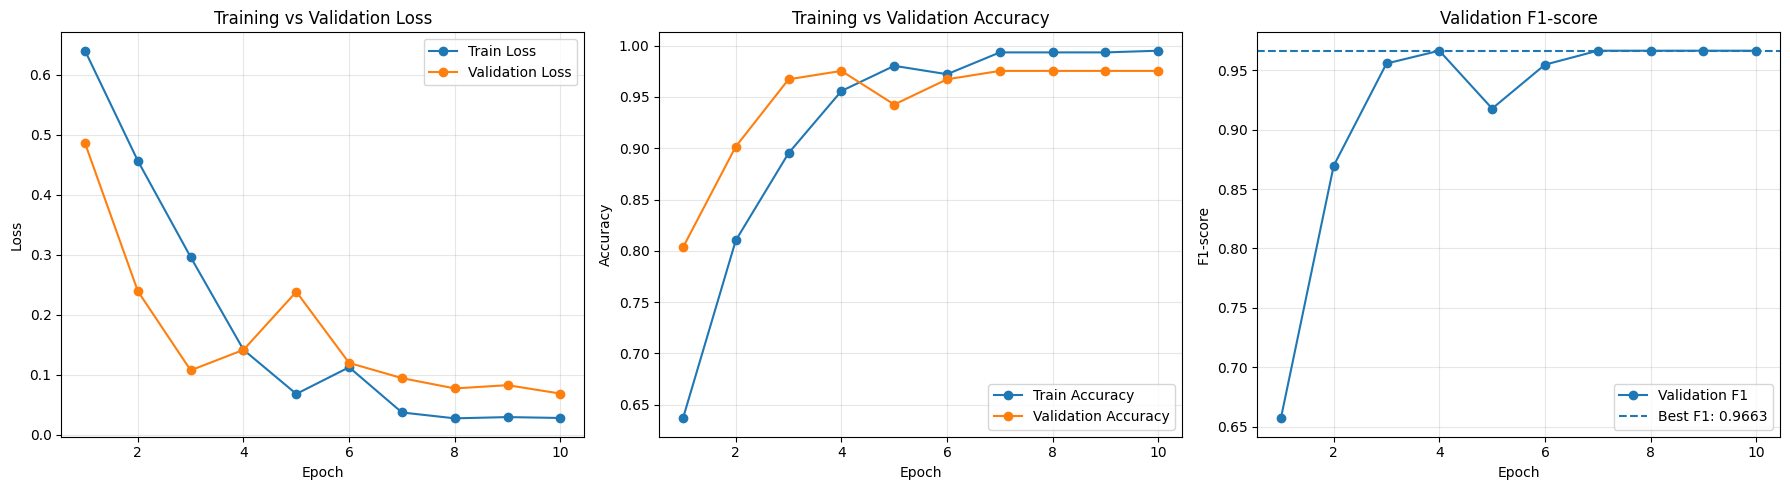

Training curves saved successfully!


In [15]:

# ============================================================
# CELL 14 — VISUALIZE TRAINING PERFORMANCE
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

epochs_range = np.arange(
    1, len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss curves
axes[0].plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)
axes[0].plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Accuracy curves
axes[1].plot(
    epochs_range,
    history["train_acc"],
    marker="o",
    label="Train Accuracy"
)
axes[1].plot(
    epochs_range,
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Validation F1 curve
axes[2].plot(
    epochs_range,
    history["val_f1"],
    marker="o",
    label="Validation F1"
)
axes[2].axhline(
    y=best_val_f1,
    linestyle="--",
    label=f"Best F1: {best_val_f1:.4f}"
)
axes[2].set_title("Validation F1-score")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1-score")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/videomae_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training curves saved successfully!")


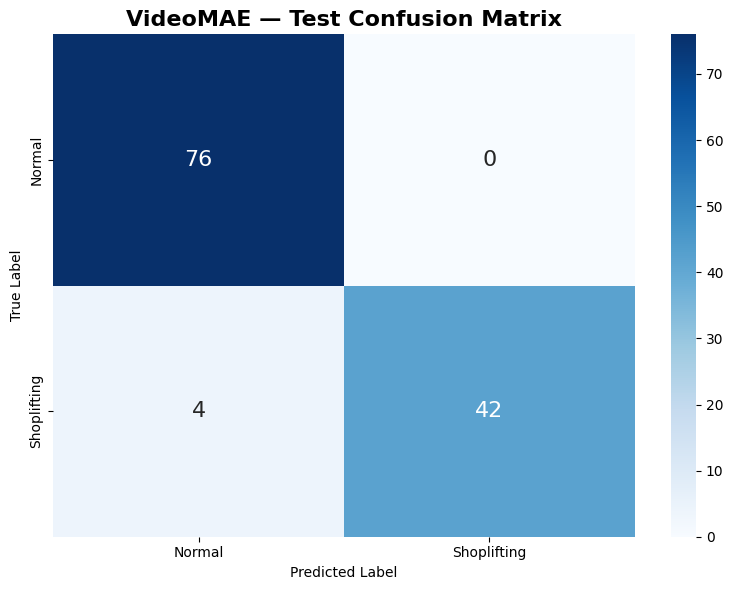

CONFUSION MATRIX ANALYSIS
True Negatives:  76
False Positives: 0
False Negatives: 4
True Positives:  42

Confusion matrix saved successfully!


In [16]:

# ============================================================
# CELL 15 — CONFUSION MATRIX VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_test_labels,
    all_test_preds,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Shoplifting"],
    yticklabels=["Normal", "Shoplifting"],
    annot_kws={"size": 16}
)

plt.title(
    "VideoMAE — Test Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/videomae_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print("=" * 50)
print("CONFUSION MATRIX ANALYSIS")
print("=" * 50)

print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

print("\nConfusion matrix saved successfully!")


In [17]:

# ============================================================
# CELL 16 — INSPECT OLD 3D CNN MODEL
# ============================================================

import os
import glob
import torch

# Search Kaggle for the old checkpoint
matches = glob.glob(
    "/kaggle/input/**/best_shoplifting_3dcnn*.pth",
    recursive=True
)

matches += glob.glob(
    "/kaggle/working/best_shoplifting_3dcnn*.pth"
)

print("=" * 60)
print("OLD 3D CNN CHECKPOINT INSPECTION")
print("=" * 60)

if not matches:
    print("Old checkpoint not found!")
    print("Please upload the Week 5 .pth file to Kaggle.")

else:
    old_model_path = matches[0]

    print("Checkpoint:", old_model_path)

    old_size_mb = (
        os.path.getsize(old_model_path) / (1024 ** 2)
    )

    print(f"Checkpoint Size: {old_size_mb:.2f} MB")

    checkpoint = torch.load(
        old_model_path,
        map_location="cpu",
        weights_only=True
    )

    if isinstance(checkpoint, dict):
        state_dict = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )

        if isinstance(state_dict, dict):
            total_old_params = sum(
                tensor.numel()
                for tensor in state_dict.values()
                if isinstance(tensor, torch.Tensor)
            )

            print(
                f"Stored Tensor Elements: "
                f"{total_old_params:,}"
            )

            print("\nFirst 5 checkpoint keys:")
            for key in list(state_dict.keys())[:5]:
                print("-", key)

    print("\nInspection completed!")


OLD 3D CNN CHECKPOINT INSPECTION
Checkpoint: /kaggle/input/datasets/nebalelshobary/best-shoplifting/best_shoplifting_3dcnn.pth
Checkpoint Size: 3.46 MB
Stored Tensor Elements: 300,950

First 5 checkpoint keys:
- block1.0.weight
- block1.1.weight
- block1.1.bias
- block1.1.running_mean
- block1.1.running_var

Inspection completed!


In [18]:

# ============================================================
# CELL 17 — RESTORE ORIGINAL WEEK 5 3D CNN
# ============================================================

import torch
import torch.nn as nn

class Shoplifting3DCNN(nn.Module):

    def __init__(self, num_classes=2):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=3,
                      padding=1, bias=False),
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2, 2)
        )

        self.block2 = nn.Sequential(
            nn.Conv3d(16, 32, kernel_size=3,
                      padding=1, bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2, 2)
        )

        self.block3 = nn.Sequential(
            nn.Conv3d(32, 64, kernel_size=3,
                      padding=1, bias=False),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2, 2)
        )

        self.block4 = nn.Sequential(
            nn.Conv3d(64, 128, kernel_size=3,
                      padding=1, bias=False),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True)
        )

        self.global_pool = nn.AdaptiveAvgPool3d(
            (1, 1, 1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.global_pool(x)
        return self.classifier(x)


# Create old model on CPU first
scratch_model = Shoplifting3DCNN(num_classes=2)

# Load saved Week 5 weights
old_checkpoint = torch.load(
    old_model_path,
    map_location="cpu",
    weights_only=True
)

old_state_dict = old_checkpoint.get(
    "model_state_dict",
    old_checkpoint.get("state_dict", old_checkpoint)
)

scratch_model.load_state_dict(
    old_state_dict,
    strict=True
)

scratch_model.eval()

# Count actual model parameters
scratch_total_params = sum(
    p.numel() for p in scratch_model.parameters()
)

print("=" * 60)
print("ORIGINAL 3D CNN RESTORED")
print("=" * 60)

print("Architecture: Shoplifting3DCNN")
print("Checkpoint loaded successfully!")
print(f"Total Parameters: {scratch_total_params:,}")
print(f"Checkpoint Size: {old_size_mb:.2f} MB")
print("Model Device: CPU")
print("Evaluation Mode:", not scratch_model.training)

print("\nReady for inference benchmarking!")


ORIGINAL 3D CNN RESTORED
Architecture: Shoplifting3DCNN
Checkpoint loaded successfully!
Total Parameters: 300,466
Checkpoint Size: 3.46 MB
Model Device: CPU
Evaluation Mode: True

Ready for inference benchmarking!


In [19]:
# ============================================================
# RE-EVALUATE WEEK 5 CNN ON EXACT WEEK 6 TEST VIDEOS
# ============================================================
# Uses the same test_df IDs as the VideoMAE test set, but this alone
# does NOT rule out Week 5 training overlap (its training manifest is missing).
class ScratchWeek6TestDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        path = os.path.join(DATASET_PATH, row["Class"], row["Video"])
        # Reuse the Week 5 uniform temporal sampling and padding logic,
        # but resize frames to Week 5's 160 x 160 input.
        cap = cv2.VideoCapture(path)
        if not cap.isOpened():
            raise ValueError(f"Cannot open: {path}")
        try:
            count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if count <= 0:
                raise ValueError(f"Empty video: {path}")
            indices = np.linspace(0, count-1, 16).astype(np.int64)
            frames = []
            for frame_idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
                success, frame = cap.read()
                if not success:
                    raise RuntimeError(f"Cannot read frame {frame_idx}: {path}")
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(resize_with_padding(frame, (160, 160)))
            frames = np.stack(frames)
        finally:
            cap.release()
        frames = np.ascontiguousarray(frames.transpose(3, 0, 1, 2),
                                      dtype=np.float32) / 255.0
        return torch.from_numpy(frames), torch.tensor(int(row["Label"]), dtype=torch.long)

scratch_test_dataset = ScratchWeek6TestDataset(test_df)
scratch_test_loader = DataLoader(scratch_test_dataset, batch_size=4,
                                  shuffle=False, num_workers=2, pin_memory=True)
scratch_eval_device = torch.device("cuda:1" if torch.cuda.device_count()>1
                                   else "cuda:0" if torch.cuda.is_available() else "cpu")
scratch_model = scratch_model.to(scratch_eval_device).eval()
scratch_labels, scratch_preds = [], []
with torch.inference_mode():
    for clips, labels in tqdm(scratch_test_loader, desc="Week 5 CNN on Week 6 test"):
        logits = scratch_model(clips.to(scratch_eval_device, non_blocking=True))
        scratch_preds.extend(logits.argmax(1).cpu().tolist())
        scratch_labels.extend(labels.tolist())

assert len(scratch_labels) == len(all_test_labels) == len(test_df)
# Both DataLoaders use shuffle=False and receive the same ordered test_df.
assert scratch_labels == all_test_labels, "Test ordering / labels mismatch!"
scratch_accuracy = accuracy_score(scratch_labels, scratch_preds)
scratch_precision = precision_score(scratch_labels, scratch_preds, zero_division=0)
scratch_recall = recall_score(scratch_labels, scratch_preds, zero_division=0)
scratch_f1 = f1_score(scratch_labels, scratch_preds, zero_division=0)
print("Same-test-set CNN metrics:", {"accuracy":scratch_accuracy,
    "precision":scratch_precision,"recall":scratch_recall,"f1":scratch_f1})
print("CNN confusion matrix:\n", confusion_matrix(scratch_labels,scratch_preds,labels=[0,1]))
print("WARNING: Week 5 training-set overlap still unverified.")

Week 5 CNN on Week 6 test:   0%|          | 0/31 [00:00<?, ?it/s]

Same-test-set CNN metrics: {'accuracy': 0.8770491803278688, 'precision': 0.803921568627451, 'recall': 0.8913043478260869, 'f1': 0.845360824742268}
CNN confusion matrix:
 [[66 10]
 [ 5 41]]


In [20]:

# ============================================================
# CELL 19 — FAIR GPU INFERENCE SPEED COMPARISON
# ============================================================

import torch
import time
import numpy as np
import pandas as pd

benchmark_device = torch.device("cuda:1" if torch.cuda.device_count() > 1 else "cuda:0")

# Original models without DataParallel
videomae_model = (
    model.module
    if isinstance(model, torch.nn.DataParallel)
    else model
)

# Preserve original VideoMAE device
original_videomae_device = next(
    videomae_model.parameters()
).device

# Move both models to the same GPU
videomae_model = videomae_model.to(benchmark_device)
scratch_model = scratch_model.to(benchmark_device)

videomae_model.eval()
scratch_model.eval()

# One video per batch, using each model's input resolution
scratch_input = torch.randn(
    1, 3, 16, 160, 160,
    device=benchmark_device
)

videomae_input = torch.randn(
    1, 16, 3, 224, 224,
    device=benchmark_device
)

def benchmark_model(model_fn, warmup=20, runs=100):

    timings = []

    with torch.inference_mode():

        for _ in range(warmup):
            model_fn()

        torch.cuda.synchronize(benchmark_device)

        for _ in range(runs):

            torch.cuda.synchronize(benchmark_device)
            start = time.perf_counter()

            model_fn()

            torch.cuda.synchronize(benchmark_device)

            timings.append(
                time.perf_counter() - start
            )

    return {
        "Mean (ms)": np.mean(timings) * 1000,
        "Std (ms)": np.std(timings) * 1000,
        "Median (ms)": np.median(timings) * 1000
    }

print("Benchmarking 3D CNN...")

scratch_speed = benchmark_model(
    lambda: scratch_model(scratch_input)
)

print("Benchmarking VideoMAE...")

videomae_speed = benchmark_model(
    lambda: videomae_model(pixel_values=videomae_input),
)

speed_df = pd.DataFrame([
    {
        "Model": "3D CNN",
        **scratch_speed
    },
    {
        "Model": "VideoMAE",
        **videomae_speed
    }
])

print("\n" + "=" * 65)
print("FAIR GPU INFERENCE BENCHMARK")
print("=" * 65)

display(speed_df.round(3))

speed_ratio = (
    videomae_speed["Mean (ms)"]
    / scratch_speed["Mean (ms)"]
)

print(
    f"\nVideoMAE / 3D CNN latency ratio: "
    f"{speed_ratio:.2f}x"
)

speed_df.to_csv(
    "/kaggle/working/model_inference_speed_comparison.csv",
    index=False
)

# AMP / fp16 measurement at batch 1, same GPU and timing methodology.
# T4 supports fp16, but speedups depend on operations and runtime.
with torch.autocast(device_type="cuda", dtype=torch.float16):
    _ = videomae_model(pixel_values=videomae_input)

def benchmark_amp(fn, warmup=20, runs=100):
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        return benchmark_model(fn, warmup=warmup, runs=runs)

scratch_amp_speed = benchmark_amp(lambda: scratch_model(scratch_input))
videomae_amp_speed = benchmark_amp(lambda: videomae_model(pixel_values=videomae_input))
print("FP16/AMP batch-1 mean latency (ms):",
      "3D CNN", round(scratch_amp_speed["Mean (ms)"],3),
      "VideoMAE", round(videomae_amp_speed["Mean (ms)"],3))

# Restore original placement after benchmarking.
videomae_model.to(original_videomae_device)

print("\nBenchmark completed!")


Benchmarking 3D CNN...
Benchmarking VideoMAE...

FAIR GPU INFERENCE BENCHMARK


,Model,Mean (ms),Std (ms),Median (ms)
0,3D CNN,3.539,0.526,3.347
1,VideoMAE,121.453,1.397,121.359



VideoMAE / 3D CNN latency ratio: 34.32x
FP16/AMP batch-1 mean latency (ms): 3D CNN 1.826 VideoMAE 32.771

Benchmark completed!


In [21]:

# ============================================================
# CELL 20 — FINAL MODEL COMPARISON TABLE
# ============================================================

import pandas as pd
import os

# Week 5 — Original 3D CNN results
# Metrics recorded from previous project
scratch_results = {
    "Model": "3D CNN (From Scratch)",
    "Accuracy (%)": scratch_accuracy * 100,
    "Precision (%)": scratch_precision * 100,
    "Recall (%)": scratch_recall * 100,
    "F1-score (%)": scratch_f1 * 100,
    "Parameters": scratch_total_params,
    "Checkpoint Size (MB)": old_size_mb,
    "FP32 latency batch=1 (ms)": scratch_speed["Mean (ms)"],
    "AMP latency batch=1 (ms)": scratch_amp_speed["Mean (ms)"]
}

# Week 6 — Fine-tuned VideoMAE results
videomae_results = {
    "Model": "VideoMAE (Pretrained)",
    "Accuracy (%)": test_accuracy * 100,
    "Precision (%)": test_precision * 100,
    "Recall (%)": test_recall * 100,
    "F1-score (%)": test_f1 * 100,
    "Parameters": total_params,
    "Checkpoint Size (MB)": model_size_mb,
    "FP32 latency batch=1 (ms)": videomae_speed["Mean (ms)"],
    "AMP latency batch=1 (ms)": videomae_amp_speed["Mean (ms)"]
}

# Combine results
final_comparison = pd.DataFrame([
    scratch_results,
    videomae_results
])

print("=" * 85)
print("FINAL MODEL COMPARISON — WEEK 5 VS WEEK 6")
print("=" * 85)

display(
    final_comparison.style.format({
        "Accuracy (%)": "{:.2f}",
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "F1-score (%)": "{:.2f}",
        "Parameters": "{:,.0f}",
        "Checkpoint Size (MB)": "{:.2f}",
        "FP32 latency batch=1 (ms)": "{:.3f}",
        "AMP latency batch=1 (ms)": "{:.3f}"
    })
)

# Performance differences
f1_improvement = (
    videomae_results["F1-score (%)"]
    - scratch_results["F1-score (%)"]
)

accuracy_improvement = (
    videomae_results["Accuracy (%)"]
    - scratch_results["Accuracy (%)"]
)

size_ratio = (
    videomae_results["Checkpoint Size (MB)"]
    / scratch_results["Checkpoint Size (MB)"]
)

speed_ratio = (
    videomae_results["FP32 latency batch=1 (ms)"]
    / scratch_results["FP32 latency batch=1 (ms)"]
)

print("\n" + "=" * 65)
print("PERFORMANCE TRADE-OFF ANALYSIS")
print("=" * 65)

print(f"F1-score Improvement: {f1_improvement:+.2f} pp")
print(f"Accuracy Improvement: {accuracy_improvement:+.2f} pp")
print(f"Checkpoint Size Ratio: {size_ratio:.2f}x")
print(f"FP32 Inference Latency Ratio: {speed_ratio:.2f}x")
print("Note: Week 5 training/test overlap remains unknown without its original manifest.")

# Export final results
output_path = (
    "/kaggle/working/final_model_comparison.csv"
)

final_comparison.to_csv(
    output_path,
    index=False
)

print("\nFinal comparison saved to:", output_path)


FINAL MODEL COMPARISON — WEEK 5 VS WEEK 6


,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%),Parameters,Checkpoint Size (MB),FP32 latency batch=1 (ms),AMP latency batch=1 (ms)
0,3D CNN (From Scratch),87.70,80.39,89.13,84.54,"300,466",3.46,3.539,1.826
1,VideoMAE (Pretrained),96.72,100.00,91.30,95.45,"86,237,954",329.05,121.453,32.771



PERFORMANCE TRADE-OFF ANALYSIS
F1-score Improvement: +10.92 pp
Accuracy Improvement: +9.02 pp
Checkpoint Size Ratio: 94.98x
FP32 Inference Latency Ratio: 34.32x
Note: Week 5 training/test overlap remains unknown without its original manifest.

Final comparison saved to: /kaggle/working/final_model_comparison.csv


# Final Discussion and Conclusion

## Objective and selection
A Kinetics-pretrained VideoMAE was selected for binary video classification because it explicitly models spatiotemporal video information and offers pretrained weights via Hugging Face. TimeSformer is another transformer-based video alternative; X3D is a compact 3D-CNN family. These alternatives were not benchmarked in this project, so no unsupported numerical comparison is claimed.

## Evaluation protocol
The original Week 5 3D CNN checkpoint is **re-evaluated on the identical ordered Week 6 `test_df`** using 16 sampled frames and 160×160 padded RGB inputs normalized to [0,1]. VideoMAE uses the corresponding 16 frames at 224×224 and its Hugging Face image processor. **Important limitation:** the original Week 5 training manifest is unavailable, so possible contamination of this shared test set by Week 5 training data cannot be ruled out. Metrics must therefore be interpreted with this caveat.

## Final same-test-set results
The best VideoMAE checkpoint obtained **96.72% test accuracy**, **100.00% precision**, **91.30% recall**, and **95.45% F1-score**, with **4 false negatives** and **0 false positives** on 122 test clips. The original Week 5 3D CNN checkpoint, evaluated on the same 122 clips, obtained **87.70% accuracy** and **84.54% F1-score**. VideoMAE exceeded the 3D CNN's F1-score by **10.92 percentage points**, but this single-split result is not a statistical significance test. Week 5 training-set overlap with this test set remains unverified.

## Accuracy, storage and latency
The final comparison table above is computed from both models' predictions on the same Week 6 test examples. VideoMAE is substantially larger than the scratch CNN. GPU timing is model-only (no video decode / preprocessing), and batch-size-1 FP32 is compared separately from batch-size-1 AMP/FP16. FP32 latency was 3.539 ms for 3D CNN versus 121.453 ms for VideoMAE (34.32×); AMP/FP16 latency was 1.826 ms versus 32.771 ms (about 17.95×). Input resolutions differ (160×160 vs 224×224) to match each model. Earlier ~29.6 ms per video is *amortized* timing at batch size 4, mixed precision, with two GPUs, and must **not** be compared directly against batch-size-1 FP32 latency.

## Limitations and next steps
A test set of 122 clips (46 shoplifting) yields uncertain estimates; one run and one split do not demonstrate statistical significance. Later training epochs showed a growing train/validation gap, while checkpointing based on validation F1 preserved the stronger epoch. The four false negatives in the VideoMAE test evaluation are important in security applications. Future work includes validating Group_ID fidelity, obtaining the Week 5 original split manifest, evaluating confidence intervals on paired predictions, selecting a detection threshold using validation data only, and testing early stopping / multiple seeds. These are suggested future checks, **not completed experiments**.

## Reproducibility
This notebook is configured for Kaggle datasets and Tesla T4 GPUs. The original VideoMAE weights were loaded from `MCG-NJU/videomae-base-finetuned-kinetics` with `ignore_mismatched_sizes=True` to replace the classification head. This recorded run used `transformers==5.16.1` and `torch==2.11.0+cu128`; an additional code cell remapped pretrained attention query/value bias weights and zero-initialized the key biases to resolve weight-name differences. Reproduction with different library versions may require checking that compatibility fix. The initial experiment used seeded Python/NumPy/PyTorch, but per-video augmentation used `np.random.default_rng()` without a fixed seed, so strict reproducibility is not guaranteed. This uploaded notebook contains completed Kaggle execution outputs, but the trained VideoMAE checkpoint is stored separately in Kaggle working files; attach the video dataset and original Week 5 3D CNN checkpoint before rerunning. A future fresh Restart & Run All should reproduce the workflow but may yield different metrics because augmentation was not fully seeded.